Import libraries and load your original dataset

In [33]:

# Install required libraries
!pip install -q pandas numpy matplotlib seaborn scikit-learn

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json

from IPython.display import display

SEED = 42
np.random.seed(SEED)

# Load original dataset
DATA_PATH = "/content/bus_demand.csv"

df = pd.read_csv(DATA_PATH)

# Standardize column names
df.rename(columns={
    "date": "journey_date",
    "hour": "departure_hour"
}, inplace=True)

# Convert date
df["journey_date"] = pd.to_datetime(
    df["journey_date"], errors="coerce"
)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset loaded successfully
Shape: (90651, 22)
Columns: ['trip_id', 'route_id', 'origin', 'destination', 'distance_km', 'route_type', 'departure_datetime', 'capacity', 'ticket_fare_inr', 'planned_event_flag', 'public_holiday_flag', 'disruption_flag', 'passengers', 'journey_date', 'departure_hour', 'weekday', 'month', 'season', 'is_weekend', 'is_peak', 'occupancy_rate', 'is_full']


,trip_id,route_id,origin,destination,distance_km,route_type,departure_datetime,capacity,ticket_fare_inr,planned_event_flag,...,passengers,journey_date,departure_hour,weekday,month,season,is_weekend,is_peak,occupancy_rate,is_full
0,R11-20240101-05,R11,Patiala,Chandigarh,65,commuter,01-01-2024 05:00,40.0,125.53,0,...,12,2024-01-01,5,0,1,winter,0,0,0.300,0
1,R06-20240101-05,R06,Amritsar,Pathankot,110,intercity,01-01-2024 05:15,40.0,178.66,0,...,15,2024-01-01,5,0,1,winter,0,0,0.375,0
2,R02-20240101-05,R02,Amritsar,Delhi,450,intercity,01-01-2024 05:45,50.0,781.36,0,...,36,2024-01-01,5,0,1,winter,0,0,0.720,0
3,R01-20240101-06,R01,Amritsar,Chandigarh,230,intercity,01-01-2024 06:15,45.0,465.83,0,...,45,2024-01-01,6,0,1,winter,0,1,1.000,1
4,R06-20240101-06,R06,Amritsar,Pathankot,110,intercity,01-01-2024 06:15,40.0,194.49,0,...,21,2024-01-01,6,0,1,winter,0,1,0.525,0


# Step 2: Initial Data Quality Report

In this step, we analyze the structure of the dataset. We check data types, look for missing values across all columns, count exact duplicate rows, and inspect the summary statistics for numerical features.

In [34]:
df.info()

missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
print("MISSING VALUE REPORT")
display(missing_report.sort_values("Missing Percentage", ascending=False))

print("Exact duplicate rows:", df.duplicated().sum())
if "trip_id" in df.columns:
    print("Duplicate trip IDs:", df["trip_id"].duplicated().sum())

display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90651 entries, 0 to 90650
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   trip_id              90651 non-null  object        
 1   route_id             90651 non-null  object        
 2   origin               90651 non-null  object        
 3   destination          90651 non-null  object        
 4   distance_km          90651 non-null  int64         
 5   route_type           90651 non-null  object        
 6   departure_datetime   90651 non-null  object        
 7   capacity             90199 non-null  float64       
 8   ticket_fare_inr      89745 non-null  float64       
 9   planned_event_flag   90651 non-null  int64         
 10  public_holiday_flag  90651 non-null  int64         
 11  disruption_flag      90651 non-null  int64         
 12  passengers           90651 non-null  int64         
 13  journey_date         35777 non-

,Missing Count,Missing Percentage
journey_date,54874,60.53
ticket_fare_inr,906,1.00
capacity,452,0.50
origin,0,0.00
trip_id,0,0.00
route_id,0,0.00
route_type,0,0.00
distance_km,0,0.00
destination,0,0.00
departure_datetime,0,0.00


Exact duplicate rows: 180
Duplicate trip IDs: 180


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
trip_id,90651,90471,R01-20251027-17,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
route_id,90651,12,R05,12803,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin,90651,6,Amritsar,33980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination,90651,10,Chandigarh,27414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
distance_km,90651.0,NaN,NaN,NaN,155.534192,60.0,65.0,110.0,230.0,450.0,115.063744
route_type,90651,3,intercity,56649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_datetime,90651,49353,09-03-2026 08:30,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capacity,90199.0,NaN,NaN,NaN,43.668999,35.0,40.0,45.0,45.0,50.0,3.681407
ticket_fare_inr,89745.0,NaN,NaN,NaN,315.995382,92.64,126.41,199.14,452.46,1040.27,233.591456
planned_event_flag,90651.0,NaN,NaN,NaN,0.002449,0.0,0.0,0.0,0.0,1.0,0.049427


```markdown
# Step 3: Split Dataset Chronologically (Before Preprocessing)

To prevent data leakage, we divide our dataset into training, validation, and testing sets first. We drop rows with missing critical splitting keys (`journey_date`), sort chronologically, and split the data. All subsequent preprocessing parameters (medians, modes, etc.) will be computed strictly on the training partition.
```

In [35]:
# Remove rows missing critical splitting or target key
df_clean = df.dropna(subset=["journey_date", "route_id", "passengers"]).copy()
df_clean = df_clean[df_clean["passengers"] >= 0].copy()
df_clean = df_clean.sort_values("journey_date").reset_index(drop=True)

# Split chronologically
train_raw = df_clean[
    (df_clean["journey_date"] >= "2024-01-01") &
    (df_clean["journey_date"] <= "2025-06-30")
].copy()

validation_raw = df_clean[
    (df_clean["journey_date"] >= "2025-07-01") &
    (df_clean["journey_date"] <= "2025-12-31")
].copy()

test_raw = df_clean[
    (df_clean["journey_date"] >= "2026-01-01")
].copy()

print("Data split successfully before preprocessing!")
print(f"Train raw shape: {train_raw.shape}")
print(f"Validation raw shape: {validation_raw.shape}")
print(f"Test raw shape: {test_raw.shape}")

Data split successfully before preprocessing!
Train raw shape: (21317, 22)
Validation raw shape: (7175, 22)
Test raw shape: (7285, 22)


# Step 3: Remove Invalid Records and Split Chronologically

We clean the dataset by removing records with missing critical information (such as journey date, route ID, or passengers) and filtering out invalid negative passenger counts. We then sort the dataset and split it chronologically into training, validation, and testing sets, reserving the test set exclusively for final model evaluation.

In [36]:
df = df.dropna(subset=["journey_date", "route_id", "passengers"]).copy()
df = df[df["passengers"] >= 0].copy()
df = df.sort_values("journey_date").reset_index(drop=True)

train_raw = df[
    (df["journey_date"] >= "2024-01-01") &
    (df["journey_date"] <= "2025-06-30")
].copy()

validation_raw = df[
    (df["journey_date"] >= "2025-07-01") &
    (df["journey_date"] <= "2025-12-31")
].copy()

test_raw = df[
    (df["journey_date"] >= "2026-01-01")
].copy()

# Step 4: Remove Duplicate Journeys

We drop duplicates based on the unique identifier `trip_id` separately for training and validation sets to ensure each journey is only represented once.

In [37]:
print("Before duplicate removal")
print("Train:", len(train_raw))
print("Validation:", len(validation_raw))

train = train_raw.drop_duplicates(subset=["trip_id"]).copy()
validation = validation_raw.drop_duplicates(subset=["trip_id"]).copy()

print("\nAfter duplicate removal")
print("Train:", len(train))
print("Validation:", len(validation))
print("\nRemaining training duplicate IDs:", train["trip_id"].duplicated().sum())
print("Remaining validation duplicate IDs:", validation["trip_id"].duplicated().sum())

Before duplicate removal
Train: 21317
Validation: 7175

After duplicate removal
Train: 21276
Validation: 7164

Remaining training duplicate IDs: 0
Remaining validation duplicate IDs: 0


In [49]:
# Step 4: Remove Duplicate Journeys across all three sets
print("Before duplicate removal:")
print(f"Train: {len(train_raw)}")
print(f"Validation: {len(validation_raw)}")
print(f"Test: {len(test_raw)}")

train = train_raw.drop_duplicates(subset=['trip_id']).copy()
validation = validation_raw.drop_duplicates(subset=['trip_id']).copy()
test = test_raw.drop_duplicates(subset=['trip_id']).copy()

print("\nAfter duplicate removal:")
print(f"Train: {len(train)}")
print(f"Validation: {len(validation)}")
print(f"Test: {len(test)}")

Before duplicate removal:
Train: 21317
Validation: 7175
Test: 7285

After duplicate removal:
Train: 21276
Validation: 7164
Test: 7272


In [50]:
# Step 5: Validate and clean anomalous values across all sets
for frame in [train, validation, test]:
    if 'distance_km' in frame.columns:
        frame.loc[frame['distance_km'] <= 0, 'distance_km'] = np.nan
    if 'capacity' in frame.columns:
        frame.loc[frame['capacity'] <= 0, 'capacity'] = np.nan
    if 'ticket_fare_inr' in frame.columns:
        frame.loc[frame['ticket_fare_inr'] < 0, 'ticket_fare_inr'] = np.nan
    if 'departure_hour' in frame.columns:
        frame.loc[~frame['departure_hour'].between(0, 23), 'departure_hour'] = np.nan
    if 'weekday' in frame.columns:
        frame.loc[~frame['weekday'].between(0, 6), 'weekday'] = np.nan

print("Anomalous and physically impossible values cleaned across Train, Validation, and Test.")

Anomalous and physically impossible values cleaned across Train, Validation, and Test.


In [51]:
# Step 6: Route-Wise and Global Median Imputation on Train, Validation, and Test sets
NUMERIC_COLUMNS = ['distance_km', 'capacity', 'ticket_fare_inr']

for col in NUMERIC_COLUMNS:
    if col not in train.columns:
        continue

    # Learn parameters STRICTLY from the training set
    route_medians = train.groupby('route_id')[col].median()
    global_median = train[col].median()

    # Apply individually to each dataset
    train[col] = train[col].fillna(train['route_id'].map(route_medians)).fillna(global_median)
    validation[col] = validation[col].fillna(validation['route_id'].map(route_medians)).fillna(global_median)
    test[col] = test[col].fillna(test['route_id'].map(route_medians)).fillna(global_median)

print("Numerical missing values imputed individually.")

Numerical missing values imputed individually.


In [52]:
# Step 7: Mode Imputation on Train, Validation, and Test sets
CATEGORICAL_COLUMNS = ['origin', 'destination', 'route_type', 'season']
BINARY_COLUMNS = ['planned_event_flag', 'public_holiday_flag', 'is_weekend', 'is_peak']

for col in CATEGORICAL_COLUMNS + BINARY_COLUMNS:
    if col not in train.columns:
        continue

    # Learn mode from train
    mode_values = train[col].mode(dropna=True)
    if len(mode_values) == 0:
        continue
    fill_value = mode_values.iloc[0]

    # Impute individually
    train[col] = train[col].fillna(fill_value)
    validation[col] = validation[col].fillna(fill_value)
    test[col] = test[col].fillna(fill_value)

print("Categorical and binary features imputed individually.")

Categorical and binary features imputed individually.


In [53]:
# Step 10 & 11: Feature Engineering and Leakage Column Removal across all three datasets
for frame in [train, validation, test]:
    if 'ticket_fare_inr' in frame.columns:
        frame['ticket_fare_log'] = np.log1p(frame['ticket_fare_inr'])

LEAKAGE_COLUMNS = ['disruption_flag', 'occupancy_rate', 'is_full']
train = train.drop(columns=LEAKAGE_COLUMNS, errors='ignore')
validation = validation.drop(columns=LEAKAGE_COLUMNS, errors='ignore')
test = test.drop(columns=LEAKAGE_COLUMNS, errors='ignore')

print("Features engineered and leakage columns dropped individually across Train, Validation, and Test.")

Features engineered and leakage columns dropped individually across Train, Validation, and Test.


In [54]:
# Save all three preprocessed datasets individually
OUTPUT_DIR = '/content/preprocessed_data'
os.makedirs(OUTPUT_DIR, exist_ok=True)

train.to_csv(f'{OUTPUT_DIR}/train_preprocessed.csv', index=False)
validation.to_csv(f'{OUTPUT_DIR}/validation_preprocessed.csv', index=False)
test.to_csv(f'{OUTPUT_DIR}/test_preprocessed.csv', index=False)

print("All 3 preprocessed datasets successfully saved:")
print(f"Train shape: {train.shape}")
print(f"Validation shape: {validation.shape}")
print(f"Test shape: {test.shape}")

All 3 preprocessed datasets successfully saved:
Train shape: (21276, 20)
Validation shape: (7164, 20)
Test shape: (7272, 20)


# Step 5: Validate Numerical Values

We verify that numerical variables fall within reasonable real-world bounds. Impossible values (e.g. non-positive distances, negative fares, or invalid hours) are flagged and replaced with NaN values so they can be imputed systematically.

In [38]:
numeric_checks = {
    "distance_km": lambda x: x <= 0,
    "capacity": lambda x: x <= 0,
    "ticket_fare_inr": lambda x: x < 0,
    "departure_hour": lambda x: (x < 0) | (x > 23),
    "weekday": lambda x: (x < 0) | (x > 6),
    "month": lambda x: (x < 1) | (x > 12),
    "passengers": lambda x: x < 0
}

print("INVALID VALUE REPORT")
for col, condition in numeric_checks.items():
    if col in train.columns:
        invalid_count = condition(train[col].dropna()).sum()
        print(f"{col}: {invalid_count}")

for frame in [train, validation]:
    if "distance_km" in frame.columns:
        frame.loc[frame["distance_km"] <= 0, "distance_km"] = np.nan
    if "capacity" in frame.columns:
        frame.loc[frame["capacity"] <= 0, "capacity"] = np.nan
    if "ticket_fare_inr" in frame.columns:
        frame.loc[frame["ticket_fare_inr"] < 0, "ticket_fare_inr"] = np.nan
    if "departure_hour" in frame.columns:
        frame.loc[~frame["departure_hour"].between(0, 23), "departure_hour"] = np.nan
    if "weekday" in frame.columns:
        frame.loc[~frame["weekday"].between(0, 6), "weekday"] = np.nan

INVALID VALUE REPORT
distance_km: 0
capacity: 0
ticket_fare_inr: 0
departure_hour: 0
weekday: 0
month: 0
passengers: 0


# Step 6: Handle Missing Numerical Values using Route-Wise Median

We impute missing numerical columns using the median of their respective route, which is less sensitive to extreme outliers. The route medians and overall global fallback medians are calculated strictly from the training set and applied to both training and validation sets to prevent data leakage.

In [39]:
NUMERIC_COLUMNS = ["distance_km", "capacity", "ticket_fare_inr"]
imputation_metadata = {}

for col in NUMERIC_COLUMNS:
    if col not in train.columns:
        continue

    route_medians = train.groupby("route_id")[col].median()
    global_median = train[col].median()

    imputation_metadata[col] = {
        "route_medians": route_medians.to_dict(),
        "global_median": float(global_median)
    }

    train[col] = train[col].fillna(train["route_id"].map(route_medians)).fillna(global_median)
    validation[col] = validation[col].fillna(validation["route_id"].map(route_medians)).fillna(global_median)

# Step 7: Handle Categorical and Binary Missing Values

We handle missing values in categorical and binary features by imputing them with the most frequent value (mode) derived strictly from the training set.

In [40]:
CATEGORICAL_COLUMNS = ["origin", "destination", "route_type", "season"]
BINARY_COLUMNS = ["planned_event_flag", "public_holiday_flag", "is_weekend", "is_peak"]

categorical_metadata = {}
for col in CATEGORICAL_COLUMNS + BINARY_COLUMNS:
    if col not in train.columns:
        continue
    mode_values = train[col].mode(dropna=True)
    if len(mode_values) == 0:
        continue
    fill_value = mode_values.iloc[0]
    categorical_metadata[col] = fill_value

    train[col] = train[col].fillna(fill_value)
    validation[col] = validation[col].fillna(fill_value)

# Step 8: Outlier Analysis and Treatment

We analyze outliers using the Interquartile Range (IQR) method and inspect their distribution. Based on domain knowledge, we choose to preserve valid extreme observations since they correspond to real variations in routes, schedules, and peak demand.

In [41]:
OUTLIER_COLUMNS = ["distance_km", "capacity", "ticket_fare_inr", "passengers"]
outlier_results = []

for col in OUTLIER_COLUMNS:
    if col not in train.columns:
        continue
    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((train[col] < lower) | (train[col] > upper)).sum()
    outlier_results.append({
        "Feature": col, "Q1": q1, "Q3": q3, "IQR": iqr, "Lower Bound": lower, "Upper Bound": upper, "Outliers Count": count
    })

display(pd.DataFrame(outlier_results))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers Count
0,distance_km,65.0000,230.000,165.0000,-182.50000,477.50000,0
1,capacity,40.0000,45.000,5.0000,32.50000,52.50000,0
2,ticket_fare_inr,125.6375,449.895,324.2575,-360.74875,936.28125,148
3,passengers,22.0000,40.000,18.0000,-5.00000,67.00000,44


# Step 8.1: Visualize Outliers

We plot histograms and boxplots for each numerical feature to visualize the presence and spread of extreme values.

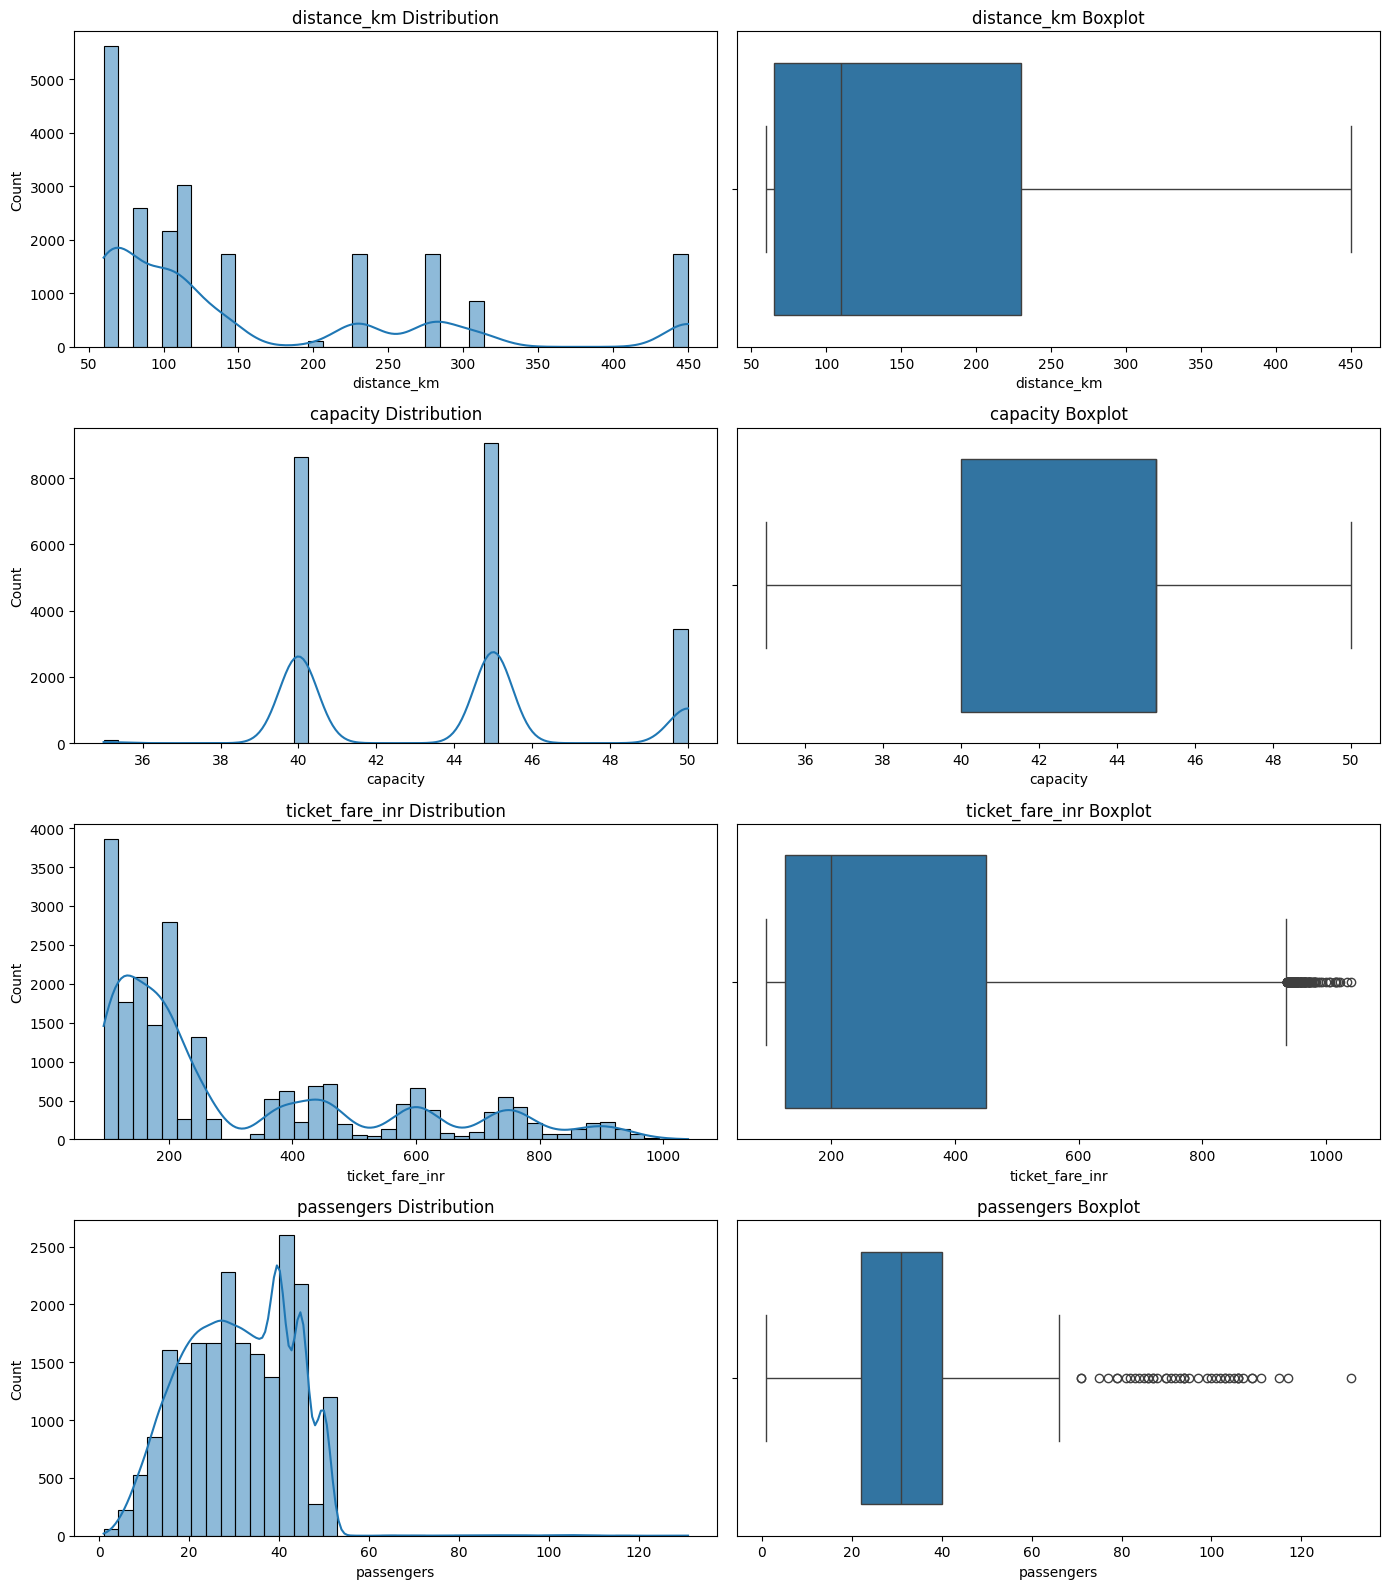

In [42]:
fig, axes = plt.subplots(len(OUTLIER_COLUMNS), 2, figsize=(14, 4 * len(OUTLIER_COLUMNS)))
for i, col in enumerate(OUTLIER_COLUMNS):
    if col not in train.columns:
        continue
    sns.histplot(train[col], bins=40, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} Distribution")
    sns.boxplot(x=train[col], ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} Boxplot")
plt.tight_layout()
plt.show()

# Step 8.2: Apply Outlier Decisions

We do not perform automatic capping or deletion because high-demand events, long routes, and standard bus capacities are actual domain dynamics.

In [43]:
print("Outlier treatment:")
print("distance_km: Preserved")
print("capacity: Preserved")
print("ticket_fare_inr: Preserved")
print("passengers: Preserved")

Outlier treatment:
distance_km: Preserved
capacity: Preserved
ticket_fare_inr: Preserved
passengers: Preserved


# Step 9: Investigate Passenger Count against Capacity

We compare passenger demand with vehicle capacity. High demand exceeding standard capacity points towards booking and reservation queues, so we keep these as audit features instead of modifying the raw target.

In [44]:
train["above_capacity"] = (train["passengers"] > train["capacity"])
print("Training records above capacity:", train["above_capacity"].sum())
print("Percentage above capacity:", round(train["above_capacity"].mean() * 100, 2), "%")
display(train.loc[train["above_capacity"], ["route_id", "passengers", "capacity"]].head(15))

Training records above capacity: 48
Percentage above capacity: 0.23 %


,route_id,passengers,capacity
310,R06,66,40.0
501,R03,87,45.0
729,R03,115,45.0
1325,R04,84,45.0
1863,R07,94,40.0
2029,R05,95,40.0
2724,R03,88,45.0
3319,R07,64,40.0
3930,R09,103,50.0
4104,R11,83,40.0


# Step 10: Investigate High Fares by Route

We generate a summary of fare statistics grouped by route ID to determine if exceptionally high values represent realistic differences between routes.

In [45]:
fare_report = train.groupby("route_id")["ticket_fare_inr"].agg(["min", "median", "mean", "max", "count"]).sort_values("max", ascending=False)
display(fare_report.round(2))

train["ticket_fare_log"] = np.log1p(train["ticket_fare_inr"])
validation["ticket_fare_log"] = np.log1p(validation["ticket_fare_inr"])
print("Log fare feature created.")

,min,median,mean,max,count
route_id,,,,,
R08,778.03,900.26,901.03,1040.27,864
R02,647.16,749.78,750.97,882.05,1728
R09,525.40,600.47,600.67,698.96,1728
R12,454.78,518.48,519.84,597.84,108
R01,386.45,450.26,450.74,519.02,1728
R07,329.85,379.96,380.16,436.31,1296
R10,213.31,250.52,250.36,289.65,1728
R04,160.57,199.64,199.93,235.92,2160
R06,166.83,190.30,190.28,221.50,1728


Log fare feature created.


# Step 11: Exclude Leakage Columns

We drop target-related indicators that are not known before a trip starts to ensure our model generalizes properly in real-time prediction environments.

In [46]:
LEAKAGE_COLUMNS = ["disruption_flag", "occupancy_rate", "is_full"]
train = train.drop(columns=LEAKAGE_COLUMNS, errors="ignore")
validation = validation.drop(columns=LEAKAGE_COLUMNS, errors="ignore")

assert "passengers" in train.columns
assert "passengers" in validation.columns
print("Leakage columns removed.\nTraining columns:", train.columns.tolist())

Leakage columns removed.
Training columns: ['trip_id', 'route_id', 'origin', 'destination', 'distance_km', 'route_type', 'departure_datetime', 'capacity', 'ticket_fare_inr', 'planned_event_flag', 'public_holiday_flag', 'passengers', 'journey_date', 'departure_hour', 'weekday', 'month', 'season', 'is_weekend', 'is_peak', 'above_capacity', 'ticket_fare_log']


# Step 12: Final Quality Checks

We perform a last review of the processed datasets to verify there are no lingering missing values, unexpected duplicate IDs, or invalid passenger numbers before saving.

In [47]:
print("=" * 50)
print("FINAL PREPROCESSING QUALITY REPORT")
print("=" * 50)
for name, frame in [("TRAIN", train), ("VALIDATION", validation)]:
    print(f"\n{name}")
    print("Shape:", frame.shape)
    print("Missing values:", frame.isnull().sum().sum())
    print("Duplicate trip IDs:", frame["trip_id"].duplicated().sum())
    print("Negative passengers:", (frame["passengers"] < 0).sum())
    display(frame.isnull().sum().to_frame("Missing Count").query("`Missing Count` > 0"))

FINAL PREPROCESSING QUALITY REPORT

TRAIN
Shape: (21276, 21)
Missing values: 0
Duplicate trip IDs: 0
Negative passengers: 0


,Missing Count



VALIDATION
Shape: (7164, 20)
Missing values: 0
Duplicate trip IDs: 0
Negative passengers: 0


,Missing Count


# Step 13 & 14: Save and Verify Preprocessed Datasets

We strip the temporary audit indicators, write the datasets to CSV format, and construct verification reports from the reloaded files.

In [48]:
train.drop(columns=["above_capacity"], errors="ignore", inplace=True)
validation.drop(columns=["above_capacity"], errors="ignore", inplace=True)

OUTPUT_DIR = "/content/preprocessed_data"
os.makedirs(OUTPUT_DIR, exist_ok=True)

train.to_csv(f"{OUTPUT_DIR}/train_preprocessed.csv", index=False)
validation.to_csv(f"{OUTPUT_DIR}/validation_preprocessed.csv", index=False)

train_clean = pd.read_csv(f"{OUTPUT_DIR}/train_preprocessed.csv")
validation_clean = pd.read_csv(f"{OUTPUT_DIR}/validation_preprocessed.csv")

print("FINAL DATASET SUMMARY")
print("Training shape:", train_clean.shape)
print("Validation shape:", validation_clean.shape)
print("\nTraining missing values:", train_clean.isnull().sum().sum())
print("Validation missing values:", validation_clean.isnull().sum().sum())
print("\nTraining date range:", train_clean["journey_date"].min(), "to", train_clean["journey_date"].max())
print("Validation date range:", validation_clean["journey_date"].min(), "to", validation_clean["journey_date"].max())

FINAL DATASET SUMMARY
Training shape: (21276, 20)
Validation shape: (7164, 20)

Training missing values: 0
Validation missing values: 0

Training date range: 2024-01-01 to 2025-06-12
Validation date range: 2025-07-01 to 2025-12-12
